# 08 Alignment arrays: did the two-year clock exist before InSAR?

```
Created on Mon Sep 21 2026
@author: daniellelindsay
Run in opera_disp_feb13. Seconds.
```

**What this notebook does.** The USGS Bay Area alignment arrays (archive v3.0)
give a 45-year record of surface slip at Tule Pond. Six arrays span the
section; HRKT was surveyed every ~60 days from 1979 to 2007 (annually after),
so it can carry an event detector directly; HGIL is annual throughout.

1. **Arrays and InSAR side by side.** The InSAR fault-parallel stack within
   1 km of each array, datum-tied by the mean offset at the surveys inside the
   InSAR window (a vertical shift only). The survey step that brackets each
   InSAR onset, and the "event" against "quiet" survey intervals since 2015.
2. **The HRKT event history.** An event is a survey interval whose step
   exceeds the inter-event rate by a fixed 6 mm (2.3 robust sigma; the
   relative 3 sigma cut at 7.7 mm drops the visually obvious 1986, 1988 and
   1997 steps). Two passes with the same joint model as notebook 04, onsets at
   interval midpoints, and every event must carry positive fitted slip.
3. **Repeat intervals and step sizes** of the array catalogue over its whole
   45 years against the InSAR catalogue, and the merged catalogue's trend.
4. **Threshold sweep** (supplement): the same detector at 3 sigma, 6 mm and 5 mm.

Ported from `Hayward_DISP-S1/analysis/run16_AA_insar_timeseries.py`,
`run18_aa_event_history.py`, `plotting/fig_aa_history.py` and
`plotting/figS_hrkt_threshold_sweep.py`. The forced-period comb tests (run17,
run19) are not in the paper and are not ported.

**Outputs** (`outputs/08_alignment_arrays/`): `hrkt_aa_events.csv`,
`aa_insar_steps.csv`, `hrkt_threshold_sweep.csv`, `08_aa_stats.txt`, registry rows `08_*`.

**Figures**: Fig 3 (a: survey cadence, b: HRKT record with events, c: the
detection statistic, d: repeat intervals and step sizes), the six-array
comparison (supplement), the threshold sweep (supplement).

**What to check.** HRKT: 177 surveys, 14 events of 0.5 to 13 mm (median 7.4),
median repeat interval 2.8 yr against 1.9 yr for the InSAR catalogue; the
quiet interval spanning Loma Prieta (1989); HGIL's surveys since 2015 stepping
~14 mm in event years and ~0 mm in quiet years.

In [1]:
import os
import warnings

import insar_utils as utils
from TulePond_filepaths import common_paths, segments, params, paths_out, repo_dir

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Constants

In [2]:
notebook = "08_alignment_arrays"
out_dir = paths_out[notebook]
fig_dir = common_paths["fig_dir"]
os.makedirs(out_dir, exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)

stack_km = 1.0          # half-width of the InSAR stack around each array
site = "HRKT"           # the array with the dense record
thr_mm = 6.0            # detection threshold: fixed excess per survey interval (see the sweep)
n_pass = 2
win_yr, win_step = 10.0, 1.0   # moving window for the repeat-interval trend
zoom_t0 = 2015.0
loma_prieta = 1989.79
# the six arrays across the section, north -> south (latitudes from the archive summary)
sites = {"HAPP": 37.5924, "HGIL": 37.5665, "HRKT": 37.5421, "HHAN": 37.5394, "HUNI": 37.5361, "HPIN": 37.5197}

fp_ts_file = os.path.join(paths_out["03_creep_timeseries"], "fp_ts.csv")
events_file = os.path.join(paths_out["04_event_detection"], "creep_events.csv")
aa_color, insar_color, det_color = "#08306B", "#D55E00", "#0072B2"

REG = utils.Registry(notebook, common_paths, repo_dir)
REG.inputs(fp_ts_file, events_file, common_paths["aa_summary"],
           *[os.path.join(common_paths["aa_dir"], f"{c}.csv") for c in sites])

Registry for 08_alignment_arrays: run cac87539, git nogit+


## LOAD: the arrays, the InSAR stack at each, the InSAR catalogue

In [3]:
fp = pd.read_csv(fp_ts_file, index_col=0)
fp.columns = fp.columns.astype(float); fp.index = fp.index.astype(float)
t_all = fp.columns.values.astype(float)
ev = pd.read_csv(events_file)
ins = ev[ev.segment == "TULEPOND"][["onset_yr", "onset_lo", "onset_hi", "amplitude_mm", "amp_lo", "amp_hi"]] \
    .sort_values("onset_yr").reset_index(drop=True)
ins["amp_err"] = (ins.amp_hi - ins.amp_lo) / 3.92      # the 95% bootstrap bounds as 1 sigma, to match the array errors
print("InSAR onsets:", [round(x, 3) for x in ins.onset_yr])

aa_all = {code: utils.load_aa(common_paths["aa_dir"], code) for code in sites}
for code, aa in aa_all.items():
    print(f"  {code}: {len(aa)} surveys {aa.year.min():.2f} to {aa.year.max():.2f}, median spacing {np.median(np.diff(aa.year)) * 365.25:.0f} d, "
          f"{aa.cum_mm.iloc[-1] / (aa.year.max() - aa.year.min()):.2f} mm/yr over the record")


def insar_stack(code, aa):
    """InSAR FP stack within +/- stack_km of the array, tied to the array by the
    mean offset at the surveys inside the InSAR window. Returns (t, y, n rows)."""
    la = sites[code]; d = stack_km / 111.19
    sub = fp[(fp.index >= la - d) & (fp.index <= la + d)]
    sub = sub[sub.notna().sum(axis=1) > 0.5 * fp.shape[1]]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        y = np.nanmean(sub.values, axis=0)
    ok = np.isfinite(y)
    ts, y = t_all[ok], y[ok]
    in_win = aa[(aa.year >= ts.min()) & (aa.year <= ts.max())]
    off = float(np.mean(in_win.cum_mm.values - np.interp(in_win.year.values, ts, y))) if len(in_win) else float(aa.cum_mm.iloc[-1] - y[0])
    return ts, y + off, len(sub)


stacks = {code: insar_stack(code, aa) for code, aa in aa_all.items()}

InSAR onsets: [2017.099, 2019.186, 2021.107, 2023.08, 2024.984]
  HAPP: 174 surveys 1979.73 to 2024.68, median spacing 64 d, 6.00 mm/yr over the record
  HGIL: 45 surveys 1983.76 to 2024.93, median spacing 365 d, 5.99 mm/yr over the record
  HRKT: 177 surveys 1979.73 to 2024.72, median spacing 63 d, 5.73 mm/yr over the record
  HHAN: 30 surveys 1982.04 to 2024.72, median spacing 367 d, 6.22 mm/yr over the record
  HUNI: 34 surveys 1993.02 to 2024.82, median spacing 364 d, 6.65 mm/yr over the record
  HPIN: 36 surveys 1989.22 to 2024.82, median spacing 370 d, 7.21 mm/yr over the record


## The arrays against the InSAR at each site

For each InSAR onset, the array step between the surveys either side of it;
and, since 2015, the median step of survey intervals that contain an InSAR
onset against those that do not. At HGIL, inside the peak zone, the array
steps ~14 mm in event years and ~0 mm between: the array's own statement
of the sawtooth.

In [4]:
L = ["08 ALIGNMENT ARRAYS", f"InSAR stack: crossings within +/-{stack_km:g} km of each array; tie: mean offset at surveys inside the InSAR window",
     "InSAR onsets: " + ", ".join(f"{x:.3f}" for x in ins.onset_yr), ""]
step_rows = []
for code, aa in aa_all.items():
    ts, yi, n = stacks[code]
    in_win = aa[(aa.year >= ts.min()) & (aa.year <= ts.max())]
    L.append(f"{code} (lat {sites[code]}), stack {n} crossings; array {aa.year.min():.2f}-{aa.year.max():.2f}, {len(aa)} surveys, "
             f"{aa.cum_mm.iloc[-1] / (aa.year.max() - aa.year.min()):.2f} mm/yr; InSAR {(yi[-1] - yi[0]) / (ts[-1] - ts[0]):.2f} mm/yr, "
             f"{len(in_win)} surveys in window")
    for on in ins.onset_yr:
        before, after = aa[aa.year < on], aa[aa.year > on]
        if len(before) and len(after):
            b_, a_ = before.iloc[-1], after.iloc[0]
            L.append(f"    {on:.3f}: array step {a_.cum_mm - b_.cum_mm:+5.1f} mm over {b_.year:.2f}-{a_.year:.2f} ({(a_.year - b_.year) * 365.25:.0f} d)")
            step_rows.append(dict(code=code, onset=on, step_mm=a_.cum_mm - b_.cum_mm, from_yr=b_.year, to_yr=a_.year))
        else:
            L.append(f"    {on:.3f}: not bracketed by surveys")
    w = aa[aa.year >= zoom_t0].reset_index(drop=True)
    ev_steps, quiet = [], []
    for i in range(1, len(w)):
        s = float(w.cum_mm.iloc[i] - w.cum_mm.iloc[i - 1])
        (ev_steps if any(w.year.iloc[i - 1] < on < w.year.iloc[i] for on in ins.onset_yr) else quiet).append(s)
    if ev_steps and quiet:
        L.append(f"    intervals since {zoom_t0:.0f}: with an event {np.median(ev_steps):+5.1f} mm (median, n = {len(ev_steps)}) vs quiet {np.median(quiet):+5.1f} mm (n = {len(quiet)})")
        step_rows.append(dict(code=code, onset=np.nan, step_mm=np.median(ev_steps), from_yr=np.nan, to_yr=np.nan, kind="event_median", n=len(ev_steps)))
        step_rows.append(dict(code=code, onset=np.nan, step_mm=np.median(quiet), from_yr=np.nan, to_yr=np.nan, kind="quiet_median", n=len(quiet)))
    L.append("")
pd.DataFrame(step_rows).to_csv(os.path.join(out_dir, "aa_insar_steps.csv"), index=False)
print("\n".join(L))

08 ALIGNMENT ARRAYS
InSAR stack: crossings within +/-1 km of each array; tie: mean offset at surveys inside the InSAR window
InSAR onsets: 2017.099, 2019.186, 2021.107, 2023.080, 2024.984

HAPP (lat 37.5924), stack 14 crossings; array 1979.73-2024.68, 174 surveys, 6.00 mm/yr; InSAR 5.57 mm/yr, 8 surveys in window
    2017.099: array step  +7.4 mm over 2016.76-2017.79 (376 d)
    2019.186: array step  +7.4 mm over 2018.80-2019.82 (371 d)
    2021.107: array step +11.3 mm over 2019.82-2021.87 (749 d)
    2023.080: array step  +7.5 mm over 2022.79-2023.86 (391 d)
    2024.984: not bracketed by surveys
    intervals since 2015: with an event  +7.4 mm (median, n = 4) vs quiet  +6.6 mm (n = 4)

HGIL (lat 37.5665), stack 23 crossings; array 1983.76-2024.93, 45 surveys, 5.99 mm/yr; InSAR 6.19 mm/yr, 8 surveys in window
    2017.099: array step +18.1 mm over 2016.76-2017.83 (388 d)
    2019.186: array step +11.4 mm over 2018.80-2019.82 (371 d)
    2021.107: array step +14.3 mm over 2019.82-2021

Saved figure to: /Users/dlindsay/tools/internal/TulePond_DISP/Figures_2026-09-21/figS_tulepond_arrays_insar_ap30-150m_coh0.7_mp5_sw200m_stack1km.png


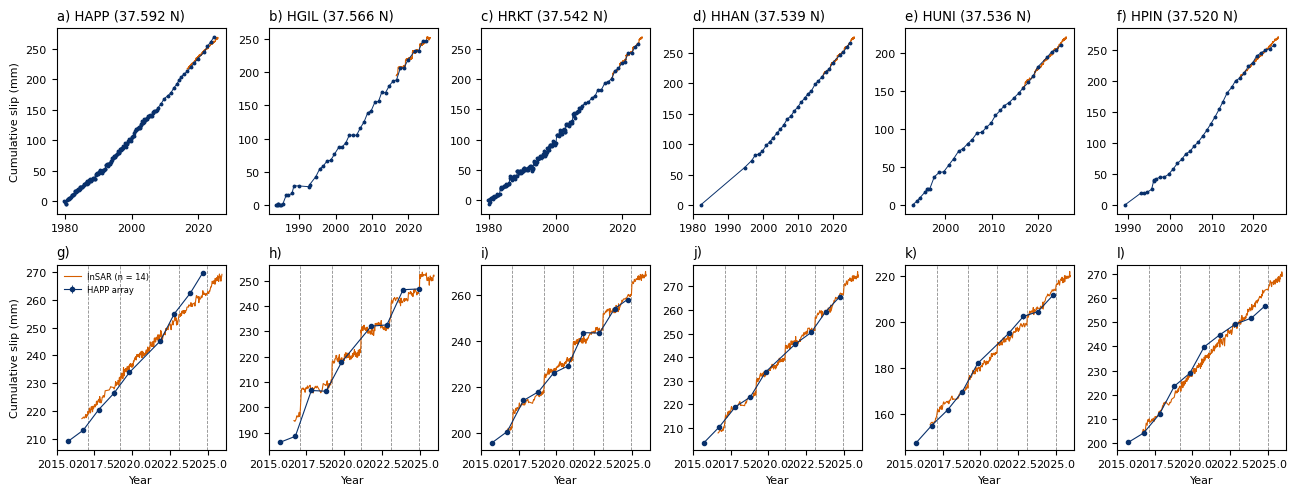

In [5]:
plt.rcParams.update({"font.size": 8})
fig, axes = plt.subplots(2, len(sites), figsize=(13.0, 5.0))
for j, (code, aa) in enumerate(aa_all.items()):
    ts, yi, n = stacks[code]
    ax = axes[0, j]
    ax.errorbar(aa.year, aa.cum_mm, yerr=aa.std_mm, fmt="o", ms=1.8, color=aa_color, ecolor=aa_color, elinewidth=0.4, lw=0.7, ls="-")
    ax.plot(ts, yi, "-", lw=0.8, color=insar_color)
    ax.set_title(f"{'abcdef'[j]}) {code} ({sites[code]:.3f} N)", loc="left")
    if j == 0: ax.set_ylabel("Cumulative slip (mm)")
    ax = axes[1, j]
    m = aa.year >= zoom_t0
    ax.errorbar(aa.year[m], aa.cum_mm[m], yerr=aa.std_mm[m], fmt="o", ms=3, color=aa_color, ecolor=aa_color, elinewidth=0.6, lw=0.8, ls="-", label=f"{code} array")
    ax.plot(ts, yi, "-", lw=0.8, color=insar_color, label=f"InSAR (n = {n})")
    for on in ins.onset_yr:
        ax.axvline(on, color="0.55", lw=0.6, ls="--", zorder=0)
    ax.set_xlim(zoom_t0, 2026.2); ax.set_xlabel("Year")
    lo = min(np.nanmin(yi), aa.cum_mm[m].min()); hi = max(np.nanmax(yi), aa.cum_mm[m].max()); ax.set_ylim(lo - 3, hi + 3)
    if j == 0:
        ax.set_ylabel("Cumulative slip (mm)"); ax.legend(fontsize=6, loc="upper left", frameon=False)
    ax.set_title(f"{'ghijkl'[j]})", loc="left")
fig.tight_layout()
f_aa = os.path.join(fig_dir, f"figS_tulepond_arrays_insar_{params}_stack{stack_km:g}km.png")
fig.savefig(f_aa, dpi=300); fig.savefig(f_aa.replace(".png", ".pdf")); print("Saved figure to:", f_aa)
plt.show()

## The HRKT event history

Detection on survey intervals: `excess = (cum_i - cum_{i-1}) - b (t_i - t_{i-1})`
beats `thr_mm`. Pass 1 uses the global rate for `b`; the flagged intervals are
fitted with the joint model (constant + rate + annual + a step per event at
the interval midpoints), any event the model gives non-positive slip is
dropped and the fit repeated; pass 2 uses the fitted inter-event rate.

In [6]:
def design(tt, onsets):
    cols = [np.ones_like(tt), tt - tt.mean(), np.sin(2 * np.pi * tt), np.cos(2 * np.pi * tt)]
    cols += [(tt > on).astype(float) for on in onsets]
    return np.column_stack(cols)


def detect_intervals(tt, cum, b, thr):
    """Survey intervals whose excess step beats thr, consecutive ones merged."""
    excess = np.diff(cum) - b * np.diff(tt)
    events = []
    for i in np.where(excess > thr)[0]:
        if events and i == events[-1][1]:
            events[-1][1] = i + 1
        else:
            events.append([i, i + 1])
    return [(a, b_) for a, b_ in events], excess


def run_detector(tt, cum, thr):
    """Two passes of detection + positive-step joint fit. Returns catalogue, excess, rate, m, G."""
    b = float(np.polyfit(tt, cum, 1)[0])
    for _ in range(n_pass):
        events, excess = detect_intervals(tt, cum, b, thr)
        while True:
            onsets = [0.5 * (tt[a] + tt[b_]) for a, b_ in events]
            G = design(tt, onsets)
            m, *_ = np.linalg.lstsq(G, cum, rcond=None)
            if not len(events) or m[4:].min() > 0:
                break
            events.pop(int(np.argmin(m[4:])))
        b = float(m[1])
    resid = cum - G @ m
    s2 = float(np.sum(resid ** 2) / (len(tt) - G.shape[1]))
    amp_se = np.sqrt(s2 * np.diag(np.linalg.inv(G.T @ G)))[4:]
    cat = pd.DataFrame([dict(onset_yr=on, onset_lo=tt[a], onset_hi=tt[b_], window_days=(tt[b_] - tt[a]) * 365.25,
                             amplitude_mm=float(A), amp_err=float(s))
                        for (a, b_), on, A, s in zip(events, onsets, m[4:], amp_se)])
    return cat, excess, b, m, G


aa = aa_all[site]; t = aa.year.values; cum = aa.cum_mm.values
cat, excess, b, m, G = run_detector(t, cum, thr_mm)
sig = utils.robust_sigma(excess)
rms = float(np.sqrt(np.mean((cum - G @ m) ** 2)))
cat.round(4).to_csv(os.path.join(out_dir, f"{site.lower()}_aa_events.csv"), index=False)
print(f"{site}: {len(t)} surveys {t.min():.2f}-{t.max():.2f}, median spacing {np.median(np.diff(t)) * 365.25:.0f} d")
print(f"threshold {thr_mm:g} mm = {thr_mm / sig:.1f} robust sigma (sigma {sig:.2f} mm); joint model: inter-event rate {b:.2f} mm/yr, "
      f"annual {np.hypot(m[2], m[3]):.2f} mm, rms {rms:.2f} mm")
print(f"{len(cat)} events, amplitudes {cat.amplitude_mm.min():.1f} to {cat.amplitude_mm.max():.1f} mm (median {cat.amplitude_mm.median():.1f})")
for r in cat.itertuples():
    print(f"  {r.onset_yr:8.3f} [{r.onset_lo:.2f}-{r.onset_hi:.2f}, {r.window_days:4.0f} d]  amp {r.amplitude_mm:5.1f} +/- {r.amp_err:.1f} mm")

HRKT: 177 surveys 1979.73-2024.72, median spacing 63 d
threshold 6 mm = 2.3 robust sigma (sigma 2.56 mm); joint model: inter-event rate 3.41 mm/yr, annual 1.70 mm, rms 2.29 mm
14 events, amplitudes 0.5 to 13.0 mm (median 7.4)
  1983.216 [1983.05-1983.39,  124 d]  amp   7.7 +/- 1.0 mm
  1986.068 [1985.95-1986.18,   85 d]  amp   5.4 +/- 1.0 mm
  1988.351 [1988.29-1988.41,   43 d]  amp   0.5 +/- 1.0 mm
  1993.265 [1993.18-1993.35,   63 d]  amp   4.6 +/- 1.0 mm
  1997.394 [1997.32-1997.47,   56 d]  amp   8.5 +/- 1.0 mm
  2000.146 [2000.06-2000.23,   63 d]  amp  11.0 +/- 1.0 mm
  2002.944 [2002.86-2003.03,   63 d]  amp   7.1 +/- 1.0 mm
  2005.081 [2004.99-2005.17,   69 d]  amp   8.3 +/- 1.4 mm
  2005.962 [2005.87-2006.06,   70 d]  amp   6.5 +/- 1.4 mm
  2012.221 [2011.81-2012.63,  302 d]  amp  10.4 +/- 2.1 mm
  2014.260 [2013.72-2014.80,  392 d]  amp   6.2 +/- 2.2 mm
  2017.289 [2016.75-2017.83,  393 d]  amp  13.0 +/- 1.9 mm
  2021.285 [2020.78-2021.80,  372 d]  amp  11.4 +/- 2.2 mm
  2023.

## Repeat intervals: the array over 45 years against the InSAR decade

The two catalogues stay separate: the array treated uniformly over its whole
record (it brackets the 2017, 2021 and 2023 events in its annual windows and
misses 2019 and 2025 just under threshold), and the InSAR catalogue as the
independent comparison. A merged catalogue (array before 2017, InSAR after)
gives the moving-window trend. The quiet interval is the longest gap between
dense-era detections; it spans Loma Prieta.

In [7]:
def interval_series(c):
    ivt = 0.5 * (c.onset_yr.values[1:] + c.onset_yr.values[:-1])
    iv = np.diff(c.onset_yr.values)
    ive = 0.5 * ((c.onset_hi - c.onset_lo).values[1:] + (c.onset_hi - c.onset_lo).values[:-1])
    return ivt, iv, ive


aa_t, aa_iv, aa_err = interval_series(cat)
in_t, in_iv, in_err = interval_series(ins)
aa_pre = cat[cat.onset_yr < ins.onset_yr.min() - 0.3]
merged = pd.concat([aa_pre[["onset_yr", "onset_lo", "onset_hi", "amplitude_mm"]].assign(src="AA"),
                    ins[["onset_yr", "onset_lo", "onset_hi", "amplitude_mm"]].assign(src="InSAR")]).sort_values("onset_yr").reset_index(drop=True)
mv_t, mv, mv_err = interval_series(merged)
mv_src = (merged.src.values[1:] == "InSAR") | (merged.src.values[:-1] == "InSAR")
mid = 0.5 * (t.min() + merged.onset_yr.max())
trend = np.polyfit(mv_t, mv, 1)
centres = np.arange(t.min() + win_yr / 2, merged.onset_yr.max() + 1e-9, win_step)
win_med = np.array([float(np.median(mv[np.abs(mv_t - c) <= win_yr / 2])) if (np.abs(mv_t - c) <= win_yr / 2).sum() else np.nan for c in centres])
dense = cat[cat.onset_yr < 2008]; gaps = np.diff(dense.onset_yr.values); iq = int(np.argmax(gaps))
quiet = (float(dense.onset_hi.values[iq]), float(dense.onset_lo.values[iq + 1]))
n_quiet = int(((t > quiet[0]) & (t < quiet[1])).sum())
max_step_quiet = float(np.max(np.diff(cum[(t >= quiet[0]) & (t <= quiet[1])])))

print(f"repeat intervals, array only: n = {len(aa_iv)}, median {np.median(aa_iv):.2f} yr; step size median {cat.amplitude_mm.median():.1f} mm (n = {len(cat)})")
print(f"repeat intervals, InSAR: n = {len(in_iv)}, median {np.median(in_iv):.2f} yr; step size median {ins.amplitude_mm.median():.1f} mm (n = {len(ins)})")
print(f"merged (array < {ins.onset_yr.min():.0f} + InSAR): n = {len(mv)}, median {np.median(mv):.2f} yr; first half (< {mid:.0f}) {np.median(mv[mv_t < mid]):.2f} yr (n = {(mv_t < mid).sum()}), "
      f"second half {np.median(mv[mv_t >= mid]):.2f} yr (n = {(mv_t >= mid).sum()}); linear trend {trend[0] * 10:+.2f} yr per decade")
print(f"quiet interval {quiet[0]:.2f} to {quiet[1]:.2f} ({quiet[1] - quiet[0]:.1f} yr): {n_quiet} surveys, largest step {max_step_quiet:.1f} mm; Loma Prieta {loma_prieta}")

repeat intervals, array only: n = 13, median 2.80 yr; step size median 7.4 mm (n = 14)
repeat intervals, InSAR: n = 4, median 1.95 yr; step size median 8.8 mm (n = 5)
merged (array < 2017 + InSAR): n = 15, median 2.28 yr; first half (< 2002) 2.82 yr (n = 6), second half 2.04 yr (n = 9); linear trend -0.35 yr per decade
quiet interval 1988.41 to 1993.18 (4.8 yr): 30 surveys, largest step 3.7 mm; Loma Prieta 1989.79


## Figure 3: the 45-year history at Tule Pond

Saved Fig 3 to: /Users/dlindsay/tools/internal/TulePond_DISP/Figures_2026-09-21/fig3_aa_history_thr6mm_nev14.png


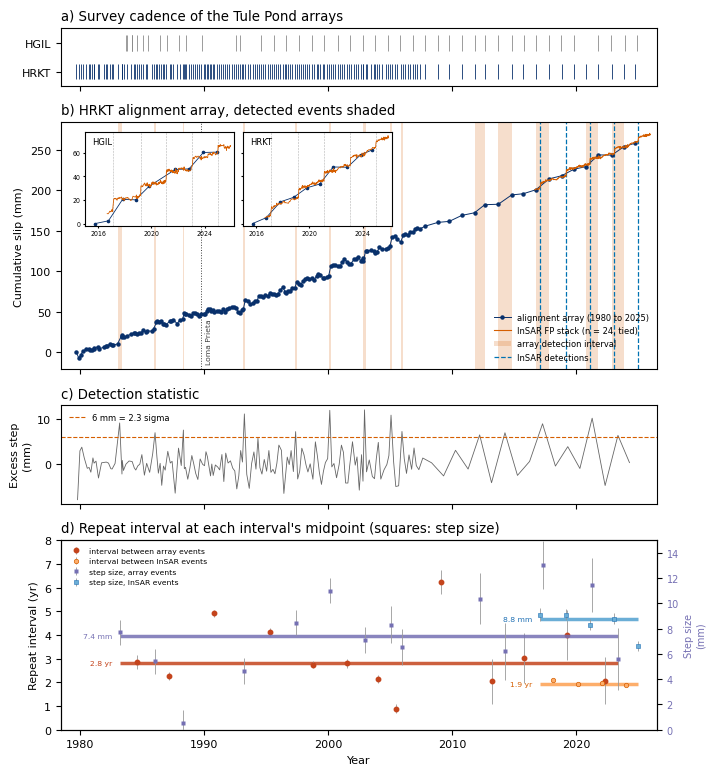

In [8]:
fig, axes = plt.subplots(4, 1, figsize=(7.2, 7.8), sharex=True, height_ratios=[0.35, 1.5, 0.6, 1.15])
hgil = aa_all["HGIL"]
ax = axes[0]
ax.eventplot([hgil.year.values, t], lineoffsets=[1, 0], linelengths=0.55, colors=["0.55", aa_color], lw=0.6)
ax.set_yticks([1, 0]); ax.set_yticklabels(["HGIL", "HRKT"]); ax.set_ylim(-0.5, 1.5)
ax.set_title("a) Survey cadence of the Tule Pond arrays", loc="left")
ax = axes[1]
t_i, y_i, n_i = stacks[site]
ax.plot(t, cum, "o", ms=2.2, color=aa_color, lw=0.7, ls="-", zorder=3, label=f"alignment array ({t.min():.0f} to {t.max():.0f})")
ax.plot(t_i, y_i, "-", lw=0.8, color=insar_color, zorder=5, label=f"InSAR FP stack (n = {n_i}, tied)")
for r in cat.itertuples():
    ax.axvspan(r.onset_lo, r.onset_hi, color=insar_color, alpha=0.20, lw=0, zorder=1, label="array detection interval" if r.Index == 0 else None)
for k, on in enumerate(ins.onset_yr):
    ax.axvline(on, color=det_color, lw=0.9, ls="--", zorder=2, label="InSAR detections" if k == 0 else None)
ax.axvline(loma_prieta, color="0.25", lw=0.7, ls=":", zorder=2)
ax.text(loma_prieta + 0.35, 0.02, "Loma Prieta", transform=ax.get_xaxis_transform(), rotation=90, fontsize=5.5, color="0.25", va="bottom")
ax.set_ylabel("Cumulative slip (mm)"); ax.legend(fontsize=6, loc="lower right", frameon=False)
ax.set_title(f"b) {site} alignment array, detected events shaded", loc="left")
zoom = {}
for code in ("HGIL", "HRKT"):
    a2 = aa_all[code]; ts, ys, _ = stacks[code]; w = a2[a2.year >= zoom_t0]
    zoom[code] = (w, ts, ys, float(w.cum_mm.iloc[0]))
z_hi = max(max(float(np.nanmax(ys)), float(w.cum_mm.max())) - z0 for w, ts, ys, z0 in zoom.values())
for k, code in enumerate(("HGIL", "HRKT")):
    w, ts, ys, z0 = zoom[code]
    axi = ax.inset_axes([0.04 + 0.265 * k, 0.58, 0.25, 0.38])
    axi.plot(w.year, w.cum_mm - z0, "o", ms=1.6, color=aa_color, lw=0.6, ls="-")
    axi.plot(ts, ys - z0, "-", lw=0.6, color=insar_color)
    for on in ins.onset_yr:
        axi.axvline(on, color="0.7", lw=0.4, ls="--", zorder=0)
    axi.set_xlim(zoom_t0, 2026.2); axi.set_ylim(-2, z_hi + 3); axi.set_xticks([2016, 2020, 2024])
    axi.tick_params(labelsize=4.5, length=1.5, pad=1.5)
    if k: axi.set_yticklabels([])
    axi.text(0.05, 0.95, code, transform=axi.transAxes, fontsize=6, va="top")
ax = axes[2]
ax.plot(0.5 * (t[1:] + t[:-1]), excess, "-", lw=0.6, color="0.4")
ax.axhline(thr_mm, color=insar_color, lw=0.8, ls="--", label=f"{thr_mm:g} mm = {thr_mm / sig:.1f} sigma")
ax.set_ylabel("Excess step\n(mm)"); ax.legend(fontsize=6, loc="upper left", frameon=False); ax.set_title("c) Detection statistic", loc="left")
ax = axes[3]
iv_med = dict(AA=float(np.median(aa_iv)), InSAR=float(np.median(in_iv)))
amp_med = dict(AA=float(cat.amplitude_mm.median()), InSAR=float(ins.amplitude_mm.median()))
aa_span = (float(cat.onset_yr.min()), float(cat.onset_yr.max())); ins_span = (float(ins.onset_yr.min()), float(ins.onset_yr.max()))
c_iv_aa, c_iv_ins, c_st_aa, c_st_ins = "#C4441C", "#FDAE6B", "#7570B3", "#6BAED6"
ax.errorbar(aa_t, aa_iv, yerr=aa_err, fmt="o", ms=3.2, color=c_iv_aa, ecolor="0.6", elinewidth=0.6, zorder=3, label="interval between array events")
ax.errorbar(in_t, in_iv, yerr=in_err, fmt="o", ms=3.2, mfc=c_iv_ins, mec="#D55E00", mew=0.5, ecolor="0.6", elinewidth=0.6, ls="none", zorder=3, label="interval between InSAR events")
ax.plot(aa_span, [iv_med["AA"]] * 2, "-", lw=2.5, color=c_iv_aa, alpha=0.85, zorder=2, solid_capstyle="butt")
ax.plot(ins_span, [iv_med["InSAR"]] * 2, "-", lw=2.5, color=c_iv_ins, zorder=2, solid_capstyle="butt")
ax.text(aa_span[0] - 0.6, iv_med["AA"], f"{iv_med['AA']:.1f} yr", fontsize=5.5, color=c_iv_aa, ha="right", va="center")
ax.text(ins_span[0] - 0.6, iv_med["InSAR"], f"{iv_med['InSAR']:.1f} yr", fontsize=5.5, color="#D55E00", ha="right", va="center")
ax2 = ax.twinx()
ax2.errorbar(cat.onset_yr, cat.amplitude_mm, yerr=cat.amp_err, fmt="s", ms=3.2, mfc=c_st_aa, mec="none", ecolor="0.6", elinewidth=0.6, ls="none", zorder=3, label="step size, array events")
ax2.errorbar(ins.onset_yr, ins.amplitude_mm, yerr=ins.amp_err, fmt="s", ms=3.2, mfc=c_st_ins, mec="#2171B5", mew=0.4, ecolor="0.6", elinewidth=0.6, ls="none", zorder=3, label="step size, InSAR events")
ax2.plot(aa_span, [amp_med["AA"]] * 2, "-", lw=2.5, color=c_st_aa, alpha=0.85, zorder=2, solid_capstyle="butt")
ax2.plot(ins_span, [amp_med["InSAR"]] * 2, "-", lw=2.5, color=c_st_ins, zorder=2, solid_capstyle="butt")
ax2.text(aa_span[0] - 0.6, amp_med["AA"], f"{amp_med['AA']:.1f} mm", fontsize=5.5, color=c_st_aa, ha="right", va="center")
ax2.text(ins_span[0] - 0.6, amp_med["InSAR"], f"{amp_med['InSAR']:.1f} mm", fontsize=5.5, color="#2171B5", ha="right", va="center")
ax2.set_ylim(0, 15.0); ax2.set_ylabel("Step size\n(mm)", color="#7570B3", fontsize=7); ax2.tick_params(axis="y", labelcolor="#7570B3", labelsize=7)
ax.set_ylim(0, 8); ax.set_ylabel("Repeat interval (yr)"); ax.set_xlabel("Year")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=5.5, loc="upper left", frameon=False)
ax.set_title("d) Repeat interval at each interval's midpoint (squares: step size)", loc="left")
ax.set_xlim(1978.5, 2026.5)
fig.tight_layout()
f_fig3 = os.path.join(fig_dir, f"fig3_aa_history_thr{thr_mm:g}mm_nev{len(cat)}.png")
fig.savefig(f_fig3, dpi=300); fig.savefig(f_fig3.replace(".png", ".pdf")); print("Saved Fig 3 to:", f_fig3)
plt.show()

## Threshold sweep (supplement)

The same detector at the relative 3 sigma cut, at 6 mm and at 5 mm. The 3
sigma cut drops the 1986, 1988 and 1997 steps and its sparse catalogue implies
a steep interval-shortening trend that is a detection artefact; at 5 mm
sub-noise events (fitted amplitude < 2 mm) start padding the catalogue.

       threshold  thr_mm  n_events  n_small  rate  trend_yr_per_decade
3 sigma = 8.2 mm    8.24         6        0  4.57                -3.34
            6 mm    6.00        14        1  3.41                -0.35
            5 mm    5.00        18        4  3.12                -0.10


Saved figure to: /Users/dlindsay/tools/internal/TulePond_DISP/Figures_2026-09-21/figS_hrkt_threshold_sweep_3sig-6mm-5mm.png


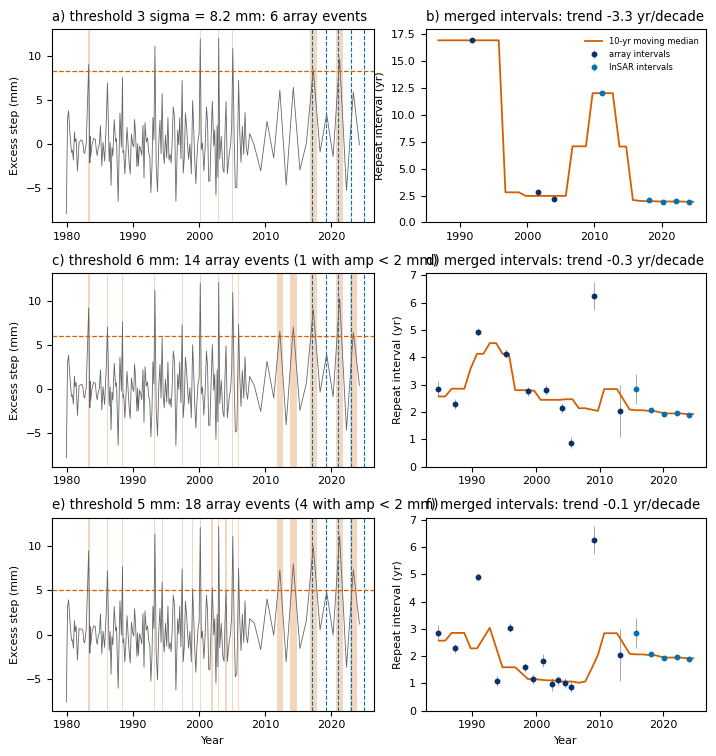

In [9]:
b0 = float(np.polyfit(t, cum, 1)[0])
_, excess0 = detect_intervals(t, cum, b0, 1e9)
sig0 = utils.robust_sigma(excess0)
cases = [(f"3 sigma = {3 * sig0:.1f} mm", 3 * sig0), ("6 mm", 6.0), ("5 mm", 5.0)]
fig, axes = plt.subplots(len(cases), 2, figsize=(7.2, 7.6), width_ratios=[1.15, 1.0])
sweep_rows = []
for row, (lab, thr) in enumerate(cases):
    c_, ex_, b_, m_, G_ = run_detector(t, cum, thr)
    pre = c_[c_.onset_yr < ins.onset_yr.min() - 0.3]
    mg = pd.concat([pre[["onset_yr", "onset_lo", "onset_hi", "amplitude_mm"]].assign(src="AA"),
                    ins[["onset_yr", "onset_lo", "onset_hi", "amplitude_mm"]].assign(src="InSAR")]).sort_values("onset_yr").reset_index(drop=True)
    mt, mvv, me = interval_series(mg); msrc = (mg.src.values[1:] == "InSAR") | (mg.src.values[:-1] == "InSAR")
    cc = np.arange(t.min() + win_yr / 2, mg.onset_yr.max() + 1e-9, win_step)
    med = [float(np.median(mvv[np.abs(mt - c) <= win_yr / 2])) if (np.abs(mt - c) <= win_yr / 2).sum() else np.nan for c in cc]
    tr_ = np.polyfit(mt, mvv, 1)
    small = int((c_.amplitude_mm < 2).sum())
    sweep_rows.append(dict(threshold=lab, thr_mm=thr, n_events=len(c_), n_small=small, rate=b_, trend_yr_per_decade=tr_[0] * 10))
    ax = axes[row, 0]
    ax.plot(0.5 * (t[1:] + t[:-1]), ex_, "-", lw=0.6, color="0.4"); ax.axhline(thr, color=insar_color, lw=0.9, ls="--")
    for r in c_.itertuples():
        ax.axvspan(r.onset_lo, r.onset_hi, color=insar_color, alpha=0.25, lw=0)
    for on in ins.onset_yr:
        ax.axvline(on, color=det_color, lw=0.8, ls="--", zorder=1)
    ax.set_ylabel("Excess step (mm)")
    ax.set_title(f"{'ace'[row]}) threshold {lab}: {len(c_)} array events" + (f" ({small} with amp < 2 mm)" if small else ""), loc="left")
    ax = axes[row, 1]
    ax.errorbar(mt[~msrc], mvv[~msrc], yerr=me[~msrc], fmt="o", ms=3.2, color=aa_color, ecolor="0.6", elinewidth=0.6, label="array intervals")
    ax.errorbar(mt[msrc], mvv[msrc], yerr=me[msrc], fmt="o", ms=3.2, mfc=det_color, mec=det_color, ecolor="0.6", elinewidth=0.6, ls="none", label="InSAR intervals")
    ax.plot(cc, med, "-", lw=1.3, color=insar_color, label=f"{win_yr:g}-yr moving median")
    ax.set_ylim(0, None); ax.set_ylabel("Repeat interval (yr)")
    ax.set_title(f"{'bdf'[row]}) merged intervals: trend {tr_[0] * 10:+.1f} yr/decade", loc="left")
    if row == 0: ax.legend(fontsize=6, loc="upper right", frameon=False)
    if row == len(cases) - 1:
        axes[row, 0].set_xlabel("Year"); ax.set_xlabel("Year")
fig.tight_layout()
sweep = pd.DataFrame(sweep_rows); sweep.to_csv(os.path.join(out_dir, "hrkt_threshold_sweep.csv"), index=False)
print(sweep.round(2).to_string(index=False))
f_sw = os.path.join(fig_dir, f"figS_hrkt_threshold_sweep_3sig-6mm-5mm.png")
fig.savefig(f_sw, dpi=300); fig.savefig(f_sw.replace(".png", ".pdf")); print("Saved figure to:", f_sw)
plt.show()

## REGISTER

In [10]:
L += [f"{site} EVENT HISTORY: record {t.min():.2f}-{t.max():.2f}, {len(t)} surveys, median spacing {np.median(np.diff(t)) * 365.25:.0f} d",
      f"detection: fixed {thr_mm:g} mm excess per interval (= {thr_mm / sig:.1f} robust sigma, sigma {sig:.2f} mm); joint model rate {b:.2f} mm/yr, annual {np.hypot(m[2], m[3]):.2f} mm, rms {rms:.2f} mm",
      f"{len(cat)} events, amplitudes {cat.amplitude_mm.min():.1f}-{cat.amplitude_mm.max():.1f} mm (median {cat.amplitude_mm.median():.1f})"]
L += [f"  {r.onset_yr:8.3f} [{r.onset_lo:.2f}-{r.onset_hi:.2f}, {r.window_days:4.0f} d]  amp {r.amplitude_mm:5.1f} mm" for r in cat.itertuples()]
L += ["", f"repeat intervals: array only n {len(aa_iv)} median {np.median(aa_iv):.2f} yr; InSAR n {len(in_iv)} median {np.median(in_iv):.2f} yr; "
      f"merged n {len(mv)} median {np.median(mv):.2f} yr, halves {np.median(mv[mv_t < mid]):.2f} / {np.median(mv[mv_t >= mid]):.2f} yr, trend {trend[0] * 10:+.2f} yr/decade",
      f"step sizes: array median {cat.amplitude_mm.median():.1f} mm (n {len(cat)}); InSAR median {ins.amplitude_mm.median():.1f} mm (n {len(ins)})",
      f"quiet interval {quiet[0]:.2f}-{quiet[1]:.2f} ({quiet[1] - quiet[0]:.1f} yr), {n_quiet} surveys, largest step {max_step_quiet:.1f} mm, spans Loma Prieta {loma_prieta}",
      "", "threshold sweep:", sweep.round(2).to_string(index=False)]
sidecar = REG.sidecar("08_aa", L)
REG.register("08_hrkt_n_surveys", len(t), "count", 0, where="P9, M8", cell="detector", sidecar=sidecar)
REG.register("08_hrkt_first_yr", t.min(), "decyear", 1, where="M8", cell="detector", sidecar=sidecar)
REG.register("08_hrkt_last_yr", t.max(), "decyear", 1, where="M8", cell="detector", sidecar=sidecar)
REG.register("08_hrkt_median_spacing_d", np.median(np.diff(t)) * 365.25, "d", 0, where="M8", cell="detector", sidecar=sidecar)
REG.register("08_hrkt_sigma_mm", sig, "mm", 2, where="M8", cell="detector", sidecar=sidecar)
REG.register("08_hrkt_threshold_sigma", thr_mm / sig, "1", 1, where="M8", cell="detector", sidecar=sidecar)
REG.register("08_hrkt_rate_mm_yr", b, "mm/yr", 2, where="M8", cell="detector", sidecar=sidecar)
REG.register("08_hrkt_annual_mm", float(np.hypot(m[2], m[3])), "mm", 1, where="M8", cell="detector", sidecar=sidecar)
REG.register("08_hrkt_n_events", len(cat), "count", 0, where="P9, M8", cell="detector", sidecar=sidecar)
REG.register("08_hrkt_amp_min_mm", cat.amplitude_mm.min(), "mm", 1, where="M8", cell="detector", sidecar=sidecar)
REG.register("08_hrkt_amp_max_mm", cat.amplitude_mm.max(), "mm", 1, where="M8", cell="detector", sidecar=sidecar)
REG.register("08_hrkt_amp_median_mm", cat.amplitude_mm.median(), "mm", 1, where="P9", cell="detector", sidecar=sidecar)
REG.register("08_aa_interval_median_yr", np.median(aa_iv), "yr", 1, where="P9", cell="intervals", sidecar=sidecar)
REG.register("08_aa_interval_n", len(aa_iv), "count", 0, where="P9", cell="intervals", sidecar=sidecar)
REG.register("08_insar_interval_median_yr", np.median(in_iv), "yr", 1, where="P9", cell="intervals", sidecar=sidecar)
REG.register("08_insar_step_median_mm", ins.amplitude_mm.median(), "mm", 1, where="P9", cell="intervals", sidecar=sidecar)
REG.register("08_merged_interval_median_yr", np.median(mv), "yr", 2, where="P9", cell="intervals", sidecar=sidecar)
REG.register("08_merged_first_half_yr", np.median(mv[mv_t < mid]), "yr", 2, where="P9", cell="intervals", sidecar=sidecar)
REG.register("08_merged_second_half_yr", np.median(mv[mv_t >= mid]), "yr", 2, where="P9", cell="intervals", sidecar=sidecar)
REG.register("08_merged_trend_yr_per_decade", trend[0] * 10, "yr/decade", 2, where="P9", cell="intervals", sidecar=sidecar)
REG.register("08_quiet_start_yr", quiet[0], "decyear", 2, where="P9", cell="intervals", sidecar=sidecar)
REG.register("08_quiet_end_yr", quiet[1], "decyear", 2, where="P9", cell="intervals", sidecar=sidecar)
REG.register("08_quiet_max_step_mm", max_step_quiet, "mm", 1, where="P9", cell="intervals", sidecar=sidecar)
REG.register("08_hrkt_dense_era_end_yr", 2007.84, "decyear", 2, where="M8", cell="detector", sidecar=sidecar)
for code in ("HGIL", "HRKT"):
    s_ = pd.DataFrame(step_rows); s_ = s_[s_.code == code]
    for kind in ("event_median", "quiet_median"):
        v = s_[s_.get("kind", pd.Series(dtype=str)) == kind]
        if len(v):
            REG.register(f"08_{code.lower()}_{kind}_mm", float(v.step_mm.iloc[0]), "mm", 1, where="P9, Fig3", cell="arrays-insar", sidecar=sidecar)
for r in sweep.itertuples():
    REG.register(f"08_sweep_{r.thr_mm:.1f}mm_n_events", r.n_events, "count", 0, where="S threshold sweep", cell="sweep", sidecar=sidecar)
    REG.register(f"08_sweep_{r.thr_mm:.1f}mm_trend", r.trend_yr_per_decade, "yr/decade", 2, where="S threshold sweep", cell="sweep", sidecar=sidecar)
REG.render()

Saved stats to: /Users/dlindsay/tools/internal/TulePond_DISP/outputs/08_alignment_arrays/08_aa_stats.txt
  registered 08_hrkt_n_surveys = 177 count  -> P9, M8
  registered 08_hrkt_first_yr = 1979.7 decyear  -> M8
  registered 08_hrkt_last_yr = 2024.7 decyear  -> M8
  registered 08_hrkt_median_spacing_d = 63 d  -> M8
  registered 08_hrkt_sigma_mm = 2.56 mm  -> M8
  registered 08_hrkt_threshold_sigma = 2.3 1  -> M8
  registered 08_hrkt_rate_mm_yr = 3.41 mm/yr  -> M8
  registered 08_hrkt_annual_mm = 1.7 mm  -> M8
  registered 08_hrkt_n_events = 14 count  -> P9, M8
  registered 08_hrkt_amp_min_mm = 0.5 mm  -> M8
  registered 08_hrkt_amp_max_mm = 13.0 mm  -> M8
  registered 08_hrkt_amp_median_mm = 7.4 mm  -> P9
  registered 08_aa_interval_median_yr = 2.8 yr  -> P9
  registered 08_aa_interval_n = 13 count  -> P9
  registered 08_insar_interval_median_yr = 1.9 yr  -> P9
  registered 08_insar_step_median_mm = 8.8 mm  -> P9
  registered 08_merged_interval_median_yr = 2.28 yr  -> P9
  registered 

  registered 08_merged_second_half_yr = 2.04 yr  -> P9
  registered 08_merged_trend_yr_per_decade = -0.35 yr/decade  -> P9
  registered 08_quiet_start_yr = 1988.41 decyear  -> P9
  registered 08_quiet_end_yr = 1993.18 decyear  -> P9
  registered 08_quiet_max_step_mm = 3.7 mm  -> P9
  registered 08_hrkt_dense_era_end_yr = 2007.84 decyear  -> M8
  registered 08_hgil_event_median_mm = 14.1 mm  -> P9, Fig3
  registered 08_hgil_quiet_median_mm = 0.4 mm  -> P9, Fig3
  registered 08_hrkt_event_median_mm = 12.0 mm  -> P9, Fig3
  registered 08_hrkt_quiet_median_mm = 3.8 mm  -> P9, Fig3
  registered 08_sweep_8.2mm_n_events = 6 count  -> S threshold sweep
  registered 08_sweep_8.2mm_trend = -3.34 yr/decade  -> S threshold sweep
  registered 08_sweep_6.0mm_n_events = 14 count  -> S threshold sweep
  registered 08_sweep_6.0mm_trend = -0.35 yr/decade  -> S threshold sweep
  registered 08_sweep_5.0mm_n_events = 18 count  -> S threshold sweep
  registered 08_sweep_5.0mm_trend = -0.10 yr/decade  -> S t

'/Users/dlindsay/tools/internal/TulePond_DISP/outputs/registry.txt'